# Echo Hiding — Proof of Concept
Python prototype of echo-hiding steganography (Gruhl, Bender & Lu): each window is convolved with
$h_b(n)=\delta(n)+a_b\,\delta(n-t_b)$, windows are merged with overlap-add, and bits are recovered from the
cepstrum autocorrelation $R_{cc}(n)=\mathcal{F}^{-1}\{\ln^2|\mathcal{F}\{x(n)\}|\}$.

In [ ]:
%matplotlib inline
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile
from IPython.display import Audio, display

FS = 44100
DELAY0_US, DELAY1_US = 1000, 1500   # echo delay for bit 0 / bit 1
ATT0_PCT, ATT1_PCT = 40, 40         # echo amplitude, % of the original
WIN_MULT = 16                       # window length = WIN_MULT * max delay
THR = 3.0                           # min robust z-score of an echo peak
GAP = 8                             # echo-less windows that end the message
CHANNEL = 0                         # 0 = left, 1 = right

C0, C1 = "#2a78d6", "#eb6834"
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
rng = np.random.default_rng(0)

## Test audio
Any CD-quality WAV (44.1 kHz, 16-bit, stereo) can be dropped in as `input.wav`; otherwise a synthetic clip is generated.

In [2]:
def synth_music(dur=30.0, fs=FS):
    n = int(dur * fs)
    t = np.arange(n) / fs
    out = np.zeros((n, 2))
    scale = 220 * 2 ** (np.array([0, 2, 4, 5, 7, 9, 11, 12]) / 12)
    step = int(0.25 * fs)
    for s in range(0, n, step):
        tt = t[:min(2 * step, n - s)]
        f0, pan = rng.choice(scale), rng.uniform(0.3, 0.7)
        note = sum(np.sin(2 * np.pi * k * f0 * tt) / k for k in range(1, 8)) * np.exp(-6 * tt)
        out[s:s + len(tt)] += note[:, None] * [1 - pan, pan]
    out += 0.15 * rng.standard_normal((n, 2)) * np.exp(-60 * (t % 0.125))[:, None]  # hi-hat
    out += 0.01 * rng.standard_normal((n, 2))
    return (0.6 * 32767 * out / np.abs(out).max()).astype(np.int16)


src = Path("input.wav")
if not src.exists():
    wavfile.write(src, FS, synth_music())
fs, audio = wavfile.read(src)
assert fs == FS and audio.dtype == np.int16 and audio.ndim == 2
x = audio[:, CHANNEL].astype(float)
print(f"{src}: {len(audio) / fs:.1f} s, {audio.shape[1]} ch, {audio.dtype}")

input.wav: 30.0 s, 2 ch, int16


## Encoder

In [3]:
d = (round(DELAY0_US * FS / 1e6), round(DELAY1_US * FS / 1e6))
a = (ATT0_PCT / 100, ATT1_PCT / 100)
L = WIN_MULT * max(d)
print(f"delays = {d} samples, window = {L} samples ({1e3 * L / FS:.1f} ms), rate = {FS / L:.1f} bit/s")


def kernel(delay, amp):
    h = np.zeros(delay + 1)
    h[0], h[delay] = 1.0, amp
    return h


def encode(x, bits, d=d, a=a, L=L):
    h = [kernel(d[0], a[0]), kernel(d[1], a[1])]
    y = np.zeros(len(x) + max(d))
    for k, s in enumerate(range(0, len(x), L)):
        v = x[s:s + L]
        yk = np.convolve(v, h[bits[k]]) if k < len(bits) else v
        y[s:s + len(yk)] += yk  # overlap-add: the N-1 tail spills into the next window
    return y[:len(x)]


for b in (0, 1):
    assert np.allclose(encode(x, [b] * (len(x) // L + 1)), np.convolve(x, kernel(d[b], a[b]))[:len(x)])
print("overlap-add == full-signal convolution")

delays = (44, 66) samples, window = 1056 samples (23.9 ms), rate = 41.8 bit/s


overlap-add == full-signal convolution


## Decoder
Windows are scaled to a fixed level so $c(0)\gg0$ and $R_{cc}(t_b)\approx 2\,c(0)\,c(t_b)$ peaks at the echo delay.

In [4]:
def rcc(v):
    v = 2**15 * v / (np.sqrt(np.mean(v**2)) + 1e-12)
    C = np.log(np.abs(np.fft.rfft(v * np.hanning(len(v)))) + 1e-12)
    return np.fft.irfft(C**2, n=len(v))


def classify(r, d=d):
    ref = r[max(d) // 2 + 1:3 * max(d)]
    med = np.median(ref)
    z = (r[list(d)] - med) / (np.median(np.abs(ref - med)) + 1e-12)  # robust z-score
    return int(np.argmax(z)), z.max()


def decode(y, d=d, L=L):
    out = np.array([classify(rcc(y[s:s + L]), d) for s in range(0, len(y) - L + 1, L)])
    return out[:, 0].astype(int), out[:, 1]

## Metadata

In [5]:
KEYS = {"title": "Title", "artist": "Artist", "author": "Author", "album": "Album",
        "year": "Year", "guest": "Guest artist", "producer": "Producer"}


def pack(meta):
    text = "".join(f"{k}={v}\n" for k, v in meta.items())
    return np.unpackbits(np.frombuffer(text.encode(), np.uint8))


def unpack(bits, z, thr=THR, gap=GAP):
    quiet = np.convolve((z < thr).astype(float), np.ones(gap), "valid") == gap
    end = np.argmax(quiet) if quiet.any() else len(bits)  # message ends at the first echo-less run
    text = np.packbits(bits[:end - end % 8]).tobytes().decode(errors="replace")
    for line in filter(None, text.split("\n")):
        key, _, val = line.partition("=")
        if key in KEYS:
            print(f"{KEYS[key]}: {val}")
        else:
            print(f"WARNING: unknown metadata {line!r}", file=sys.stderr)

## End to end

In [6]:
meta = {"title": "Echo Song", "artist": "The Cepstrals", "author": "J. Doe", "album": "LTI Hits",
        "year": "2026", "guest": "A. Delay", "producer": "M. Convolve",
        "mood": "calm"}  # unknown key -> stderr
bits = pack(meta)
assert len(bits) <= len(x) // L, "audio too short for this payload"

enc = audio.copy()
enc[:, CHANNEL] = np.clip(np.round(encode(x, bits)), -32768, 32767)
wavfile.write("encoded.wav", FS, enc)

_, rx = wavfile.read("encoded.wav")
dec, z = decode(rx[:, CHANNEL].astype(float))
has = z >= THR
print(f"payload: {len(bits)} bits in {len(bits) * L / FS:.1f} s")
print(f"recovery rate: {np.mean(dec[:len(bits)] == bits):.1%}")
print(f"echo detected: {has[:len(bits)].mean():.1%} of payload windows, {has[len(bits):].mean():.1%} of empty windows\n")
unpack(dec, z)

payload: 976 bits in 23.4 s
recovery rate: 100.0%
echo detected: 100.0% of payload windows, 1.1% of empty windows

Title: Echo Song
Artist: The Cepstrals
Author: J. Doe
Album: LTI Hits
Year: 2026
Guest artist: A. Delay
Producer: M. Convolve


In [ ]:
print("original / encoded (first 10 s)")
display(Audio(x[:10 * FS] / 32768, rate=FS, normalize=False),
        Audio(rx[:10 * FS, CHANNEL] / 32768, rate=FS, normalize=False))

## Impulse responses and cepstrum autocorrelation

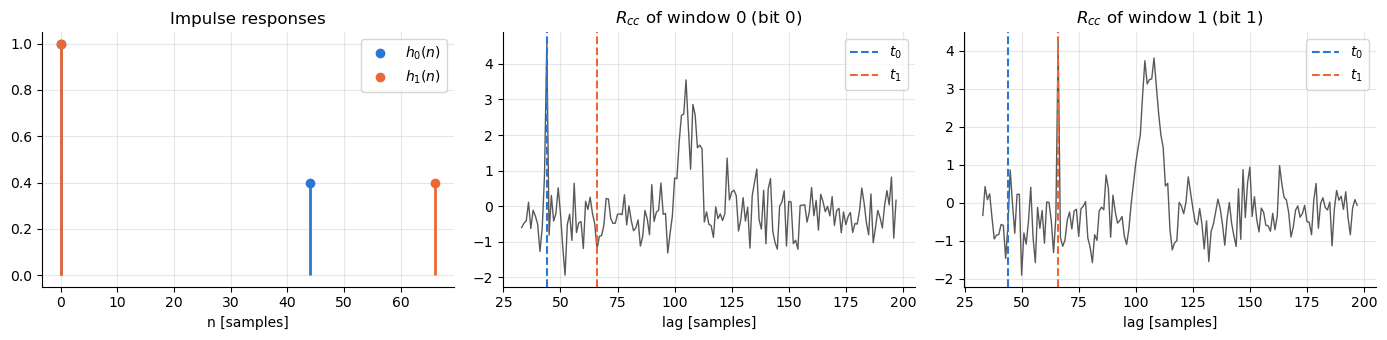

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
for b, c in ((0, C0), (1, C1)):
    n = np.flatnonzero(kernel(d[b], a[b]))
    ax[0].vlines(n, 0, kernel(d[b], a[b])[n], color=c, lw=2)
    ax[0].plot(n, kernel(d[b], a[b])[n], "o", color=c, label=f"$h_{b}(n)$")
ax[0].set(title="Impulse responses", xlabel="n [samples]")
ax[0].legend()

lags = np.arange(max(d) // 2, 3 * max(d))
for i, b in enumerate((0, 1), start=1):
    k = np.flatnonzero(bits == b)[0]
    r = rcc(rx[k * L:(k + 1) * L, CHANNEL].astype(float))
    ax[i].plot(lags, r[lags], color="0.35", lw=1)
    ax[i].axvline(d[0], color=C0, ls="--", lw=1.5, label="$t_0$")
    ax[i].axvline(d[1], color=C1, ls="--", lw=1.5, label="$t_1$")
    ax[i].set(title=f"$R_{{cc}}$ of window {k} (bit {b})", xlabel="lag [samples]")
    ax[i].legend()
fig.tight_layout()

## Parameter sweeps

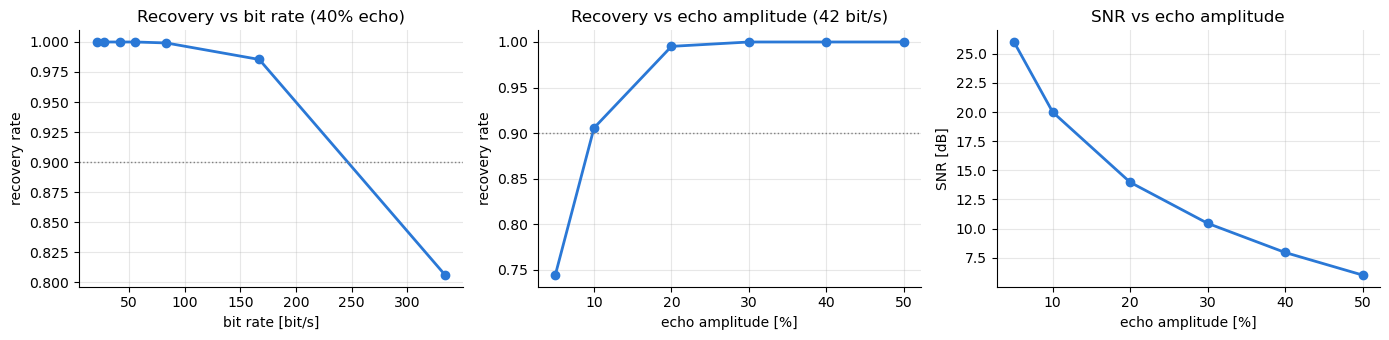

In [9]:
xs = x[:30 * FS]


def trial(att_pct=ATT0_PCT, mult=WIN_MULT):
    Lw = mult * max(d)
    b = rng.integers(0, 2, len(xs) // Lw)
    y = encode(xs, b, a=(att_pct / 100,) * 2, L=Lw)
    snr = 10 * np.log10(np.sum(xs**2) / np.sum((y - xs)**2))
    return np.mean(decode(y, L=Lw)[0] == b), snr


mults = [2, 4, 8, 12, 16, 24, 32]
atts = [5, 10, 20, 30, 40, 50]
rec_m = [trial(mult=m)[0] for m in mults]
rec_a, snr_a = zip(*[trial(att_pct=p) for p in atts])

fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
ax[0].plot([FS / (m * max(d)) for m in mults], rec_m, "o-", color=C0, lw=2)
ax[0].set(title=f"Recovery vs bit rate ({ATT0_PCT}% echo)", xlabel="bit rate [bit/s]", ylabel="recovery rate")
ax[1].plot(atts, rec_a, "o-", color=C0, lw=2)
ax[1].set(title=f"Recovery vs echo amplitude ({FS / L:.0f} bit/s)", xlabel="echo amplitude [%]", ylabel="recovery rate")
for axi in ax[:2]:
    axi.axhline(0.9, color="0.5", ls=":", lw=1)
ax[2].plot(atts, snr_a, "o-", color=C0, lw=2)
ax[2].set(title="SNR vs echo amplitude", xlabel="echo amplitude [%]", ylabel="SNR [dB]")
fig.tight_layout()